# CHLA-Z methods 3: PACE matchups

**Author:** Eli Holmes (NOAA)<br>
Last updated: November 23, 2026

> **What this notebook is.** One of four *data methods* notebooks for the
> CHLA-Z tables in `datasets/chla_z/data/`. It shows, for one day of PACE
> data, exactly how the in situ profiles (Argo and OOI, from notebooks 1 and
> 2) are matched to PACE OCI Level-3 Rrs and chlor_a. It is **not** about
> model training.
>
> **What it is not.** It does not build the tables. The full build runs from
> `datasets/chla_z/build.py`, which calls the same functions in
> `src/chla_z_build.py`. The last section checks the result against the
> released `_plus_PACE` tables.

| # | Notebook | Method | Build stage |
|---|---|---|---|
| 1 | 01-argo-retrieval-qc | BGC-Argo retrieval, QC, depth bins | `argo` |
| 2 | 02-ooi-retrieval-qc | OOI retrieval, QC, 3 h solar-time windows, Sauzède correction | `ooi-fetch`, `ooi` |
| 3 | **03-pace-matchups** | PACE Rrs, chlor_a, Kd matchups | `pace`, `pace-merge` |
| 4 | 04-olci-matchups | Sentinel-3 OLCI Rrs matchups | `olci`, `olci-merge` |

**The rules, in brief.**

1. PACE OCI V3.2 Level-3 *mapped daily* 4 km files: AOP (Rrs, 172 bands), BGC
   (chlor_a) and KD (Kd at 490 nm). NRT files are used only for days with no
   standard file (in practice, October 2026).
2. A profile matches a file when its time is in the 24 h *after* the file's
   `time_coverage_start` attribute.
3. The value is the nearest 4 km cell. No box average, no flags beyond the
   file's own masking (a masked cell is NaN).
4. If more than one file matches: standard before NRT, then the file whose
   time window centre is closest to the profile time.
5. chlor_a and Kd_490 are attached only when they come from the same day and
   stream (standard/NRT) as the Rrs file.

**What a matchup is here.** A daily L3 map composites the day's swaths and
carries no per-pixel overpass time, so this pairs a profile with the daily
map, not with the overpass. Time-of-day effects on in situ chlorophyll
(quenching) are left to the model, through `solar_hour`.

Needs a NASA Earthdata login (`~/.netrc` or interactive). Runs in about
3 minutes, most of it reading the 172 Rrs bands at the profile points. It
reads in place from NASA's S3 when run in AWS us-west-2 and over HTTPS
otherwise (slower).

In [1]:
import sys

if "../../../src" not in sys.path:
    sys.path.insert(0, "../../../src")

import earthaccess
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import chla_z_build as b

earthaccess.login()

## 1. The profiles to match

`b.pace_points()` reads the time and position of every profile from the
two released profile tables. Matching is per platform, so one platform can
be re-matched alone.

In [2]:
pts = b.pace_points()
pts.groupby("platform").size()

platform
argo    59583
ooi     95770
dtype: int64

## 2. Find one day's files

The collections, from `b.PACE_PRODUCTS`:

In [3]:
pd.DataFrame(b.PACE_PRODUCTS).T

,short_names,var,wavelength
Rrs,"[PACE_OCI_L3M_AOP, PACE_OCI_L3M_AOP_NRT]",Rrs,NaN
chlor_a,"[PACE_OCI_L3M_BGC, PACE_OCI_L3M_BGC_NRT]",chlor_a,NaN
Kd,"[PACE_OCI_L3M_KD, PACE_OCI_L3M_KD_NRT]",Kd,490.0


In [4]:
day = "2025-07-15"
found = {}
for product, cfg in b.PACE_PRODUCTS.items():
    for sn in cfg["short_names"]:
        res = earthaccess.search_data(short_name=sn, temporal=(day, day),
                                      granule_name=b.PACE_GRANULE_PATTERN)
        for g in res:
            name = g["umm"]["GranuleUR"]
            if day.replace("-", "") in name:
                found[product] = g
                print(f"{product:8s} {sn:22s} {name}")

Rrs      PACE_OCI_L3M_AOP       PACE_OCI.20250715.L3m.DAY.AOP.V3_2.4km.nc


chlor_a  PACE_OCI_L3M_BGC       PACE_OCI.20250715.L3m.DAY.BGC.V3_2.4km.nc


Kd       PACE_OCI_L3M_KD        PACE_OCI.20250715.L3m.DAY.KD.V3_2.4km.nc


No NRT file is listed for this day because the standard files exist; the
build searches both and decides when merging (rule 4).

## 3. Rrs: time window, nearest cell, read

Open the AOP file lazily (`chunks={}`): it is a 4320 × 8640 × 172 grid, about
26 GB uncompressed, and only the cells under the profiles are read.

In [5]:
f = earthaccess.open([found["Rrs"]])[0]
ds = xr.open_dataset(f, chunks={})
t_start = pd.to_datetime(ds.attrs["time_coverage_start"], utc=True)
t_end = pd.to_datetime(ds.attrs["time_coverage_end"], utc=True)
print("time_coverage_start", t_start, "\ntime_coverage_end  ", t_end)
ds["Rrs"]

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

time_coverage_start 2025-07-15 00:12:14.069000+00:00 
time_coverage_end   2025-07-16 01:02:23.960000+00:00


<xarray.DataArray 'Rrs' (lat: 4320, lon: 8640, wavelength: 172)> Size: 26GB
dask.array<open_dataset-Rrs, shape=(4320, 8640, 172), dtype=float32, chunksize=(16, 1024, 8), chunktype=numpy.ndarray>
Coordinates:
  * lat         (lat) float32 17kB 89.98 89.94 89.9 ... -89.9 -89.94 -89.98
  * lon         (lon) float32 35kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
  * wavelength  (wavelength) float32 688B 346.0 348.5 350.9 ... 716.8 719.3
Attributes:
    long_name:      Remote sensing reflectance
    units:          sr^-1
    standard_name:  surface_ratio_of_upwelling_radiance_emerging_from_sea_wat...
    valid_min:      -30000
    valid_max:      25000
    display_scale:  linear
    display_min:    0.0
    display_max:    0.025

Rule 2: profiles in [t_start, t_start + 24 h). This uses the file's
attribute, not the date in its name: a day's swaths start a little after
00 UTC and run past the next midnight.

In [6]:
sel = (pts["time"] >= t_start) & (pts["time"] < t_start + pd.Timedelta(hours=24))
rec = pts[sel].reset_index(drop=True)
rec.groupby("platform").size()

/tmp/ipykernel_412630/44216787.py:1: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  sel = (pts["time"] >= t_start) & (pts["time"] < t_start + pd.Timedelta(hours=24))


platform
argo     70
ooi     111
dtype: int64

Rule 3: the nearest grid index in lat and lon (`b._nearest_index` gives the
same answer as `ds.sel(..., method="nearest")`, for many points at once),
then one pointwise read of all 172 bands with dask `vindex`.

In [7]:
li = b._nearest_index(ds["lat"].values, rec["lat"].to_numpy(float))
lo = b._nearest_index(ds["lon"].values, rec["lon"].to_numpy(float))
rrs = np.asarray(ds["Rrs"].data.vindex[li, lo].compute(), dtype=float)
rrs.shape

(181, 172)

Band names are the band centres rounded to whole nm (`pace_Rrs_346` …
`pace_Rrs_719`). `b._rrs_labels` raises if the band set ever changes.

In [8]:
labels = b._rrs_labels(ds["wavelength"].values)
rrs_cols = [f"pace_Rrs_{x}" for x in labels]
match = pd.DataFrame(rrs, columns=rrs_cols)
match.insert(0, "profile_id", rec["profile_id"])
match.insert(1, "platform", rec["platform"])
match["pace_Rrs_lat"] = ds["lat"].values[li]
match["pace_Rrs_lon"] = ds["lon"].values[lo]
valid = match[rrs_cols].notna().any(axis=1)
print(f"{valid.sum()} of {len(match)} profiles have a non-masked PACE cell")
match.groupby("platform").apply(lambda d: d[rrs_cols].notna().any(axis=1).sum(),
                                include_groups=False)

15 of 181 profiles have a non-masked PACE cell


platform
argo    11
ooi      4
dtype: int64

Most cells are masked: cloud, glint, sea ice and the gaps between swaths.
Over the whole table, about 1 in 6 Argo and 1 in 4 OOI profiles end up with
Rrs. All the OOI matches here are 3 h windows of one instrument on one day,
so they share one pixel and one spectrum (one orange line below). That is
why a train/test split on the OOI table must be grouped by instrument.

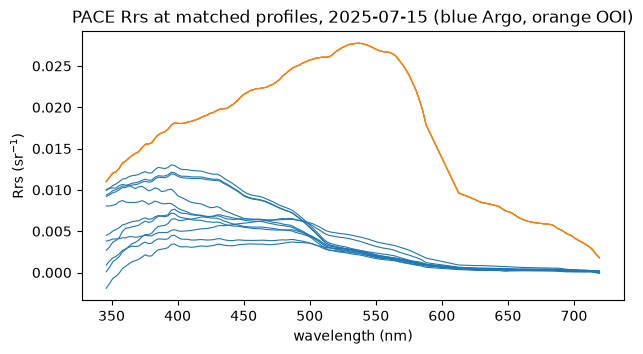

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
wl = ds["wavelength"].values
for _, r in match[valid].iterrows():
    ax.plot(wl, r[rrs_cols].to_numpy(float), lw=0.8,
            color="tab:blue" if r["platform"] == "argo" else "tab:orange")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("Rrs (sr$^{-1}$)")
ax.set_title(f"PACE Rrs at matched profiles, {day} (blue Argo, orange OOI)");

## 4. chlor_a (and Kd)

The same steps on the BGC file. Kd is the same again on the KD file, at the
band nearest 490 nm (489.674 nm); it is skipped here to save time.

In [10]:
fb = earthaccess.open([found["chlor_a"]])[0]
with xr.open_dataset(fb, chunks={}) as dsb:
    tb = pd.to_datetime(dsb.attrs["time_coverage_start"], utc=True)
    recb = pts[(pts["time"] >= tb) & (pts["time"] < tb + pd.Timedelta(hours=24))]
    assert recb["profile_id"].tolist() == rec["profile_id"].tolist()
    chl = dsb["chlor_a"].data.vindex[
        b._nearest_index(dsb["lat"].values, rec["lat"].to_numpy(float)),
        b._nearest_index(dsb["lon"].values, rec["lon"].to_numpy(float))].compute()
match["pace_chlor_a"] = np.asarray(chl, dtype=float)
match.loc[valid, ["profile_id", "platform", "pace_chlor_a", "pace_Rrs_442", "pace_Rrs_555"]].head()

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

/tmp/ipykernel_412630/2771507384.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  recb = pts[(pts["time"] >= tb) & (pts["time"] < tb + pd.Timedelta(hours=24))]


,profile_id,platform,pace_chlor_a,pace_Rrs_442,pace_Rrs_555
11,4902683_0072,argo,0.217213,0.005626,0.001978
16,4903711_0081,argo,0.500106,0.005804,0.003554
22,7901006_0226,argo,0.319855,0.006410,0.002974
30,4903847_0004,argo,0.059116,0.010212,0.001856
32,6990684_0003,argo,0.054735,0.010686,0.001986


The build does sections 3 and 4 in `b.pace_granule_unit(product, short_name,
granule, platform)`, one unit per (platform, file), and saves each to
`_temp_data/matchups_v3_2/<product>/<platform>/<file>.parquet`.

In [11]:
help(b.pace_granule_unit)

Help on function pace_granule_unit in module chla_z_build:

pace_granule_unit(
    product: 'str',
    short_name: 'str',
    granule: 'str',
    platform: 'str',
    attempts: 'int' = 5
) -> 'str'



## 5. Choosing among files and merging

A profile in the first minutes of a UTC day falls in the windows of both
that day's file and the day before's, and from April 2026 a day can have
both a standard and an NRT file. `b.pace_select` keeps one file per profile
and product (rule 4); `b.pace_merge` joins Rrs, chlor_a and Kd (rule 5) and
then the profile table, so each `_plus_PACE` table has one row per profile
with a PACE file, including the many with all-NaN Rrs.

## 6. Check against the released tables

Every released row whose Rrs file is this day's file should have the same
172 Rrs values and chlor_a as here.

In [12]:
fname = found["Rrs"]["umm"]["GranuleUR"]
for platform in b.PLATFORMS:
    rel = pd.read_parquet(b.DATA_DIR / f"CHLA_{platform}_profiles_plus_PACE.parquet")
    rel = rel[rel["pace_Rrs_file"] == fname]
    m = rel.merge(match, on="profile_id", suffixes=("_released", ""))
    same = all(np.allclose(m[c], m[f"{c}_released"], equal_nan=True)
               for c in rrs_cols + ["pace_chlor_a"])
    print(f"{platform}: {len(rel)} released rows from {fname}, {len(m)} matched here, "
          f"values equal: {same}")
    assert len(m) == len(rel) and same

argo: 70 released rows from PACE_OCI.20250715.L3m.DAY.AOP.V3_2.4km.nc, 70 matched here, values equal: True


ooi: 111 released rows from PACE_OCI.20250715.L3m.DAY.AOP.V3_2.4km.nc, 111 matched here, values equal: True


## Running the full build

```
cd datasets/chla_z
python build.py pace --product Rrs --workers 3      # ~1,140 files x 2 platforms
python build.py pace --product chlor_a --workers 3
python build.py pace --product Kd --workers 3
python build.py pace-merge   # -> data/CHLA_{argo,ooi}_profiles_plus_PACE.parquet
```

Add `--platform argo` or `--platform ooi` to match one platform. The file
list is searched once per product and cached, so reruns use the same list.
The Rrs stage is CPU-bound (decompressing 172-band chunks): about 19 h on a
4-core machine. Decisions and run log: `claude/notes/chla-z-rebuild-2026-11.md`.

How the matched in situ and PACE values compare, including the effect of
solar hour, is in `05-compare-datasets.ipynb`.

### Earlier notebook

This notebook replaces `argo-matchups.ipynb`, which ran the PACE matchups
before the build moved to `build.py`; its comparison plots are now in
notebook 05. It is kept at the release tag
[`2026_11_23`](https://github.com/fish-pace/fish-pace-datasets/blob/2026_11_23/datasets/chla_z/notebooks/argo-matchups.ipynb);
to get a local copy, run
`git checkout 2026_11_23 -- datasets/chla_z/notebooks/argo-matchups.ipynb`.